In [46]:
%pip install "qiskit==1.4.2" "qiskit-aer==0.16.1" "qiskit-machine-learning==0.8.2" "numpy<2" scikit-learn pandas matplotlib networkx

In [47]:
import qiskit
import qiskit_aer
import sklearn
import numpy
import pandas
import matplotlib
import networkx

print("Qiskit:", qiskit.__version__)
print("Qiskit Aer:", qiskit_aer.__version__)
print("NumPy:", numpy.__version__)
print("All imports successful!")

Qiskit: 1.4.2
Qiskit Aer: 0.16.1
NumPy: 1.26.4
All imports successful!


In [48]:
import qiskit
import qiskit_aer
import sklearn
import numpy
import pandas
import matplotlib
import networkx

print("Qiskit:", qiskit.__version__)
print("Qiskit Aer:", qiskit_aer.__version__)
print("scikit-learn:", sklearn.__version__)
print("All basic libraries imported successfully!")

Qiskit: 1.4.2
Qiskit Aer: 0.16.1
scikit-learn: 1.6.1
All basic libraries imported successfully!


In [49]:
from sklearn.datasets import make_classification
import pandas as pd

X, y = make_classification(
    n_samples=200,
    n_features=4,
    n_informative=3,
    n_redundant=0,
    random_state=42
)

data = pd.DataFrame(
    X,
    columns=["feature_1", "feature_2", "feature_3", "feature_4"]
)

data["label"] = y

print("Dataset shape:", X.shape)
print("Labels shape:", y.shape)
print(data.head())
print("\nClass counts:")
print(data["label"].value_counts())

Dataset shape: (200, 4)
Labels shape: (200,)
   feature_1  feature_2  feature_3  feature_4  label
0   0.235276   0.668446   0.174415   0.615936      1
1   0.579826   0.985854   1.680555  -0.363612      1
2  -0.520783   0.443419   1.080275   0.170865      1
3  -1.306467   1.929037  -1.637173  -1.110576      0
4  -0.317796  -0.501952  -0.565364   1.029156      0

Class counts:
label
1    100
0    100
Name: count, dtype: int64


In [50]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import MinMaxScaler

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

scaler = MinMaxScaler(
    feature_range=(0, 1)
)

X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

print("Training samples:", len(X_train_scaled))
print("Testing samples:", len(X_test_scaled))
print("Training features:", X_train_scaled.shape[1])

Training samples: 160
Testing samples: 40
Training features: 4


In [51]:
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score

classical_model = make_pipeline(
    StandardScaler(),
    LogisticRegression(random_state=42, max_iter=1000)
)

classical_model.fit(X_train, y_train)

classical_predictions = classical_model.predict(X_test)

classical_accuracy = accuracy_score(
    y_test,
    classical_predictions
)

print("Classical test accuracy:", classical_accuracy)

Classical test accuracy: 0.9


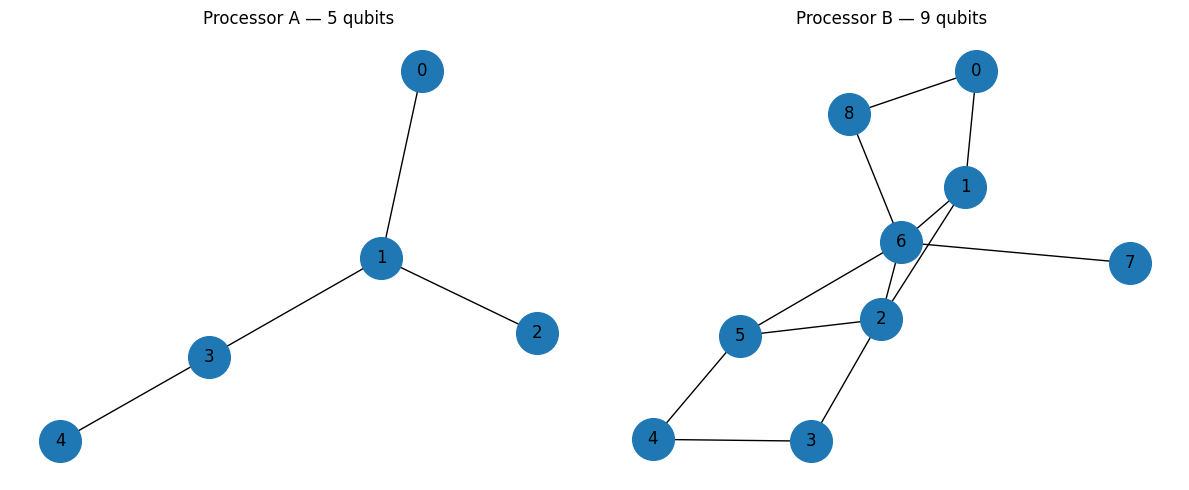

In [52]:
import networkx as nx
import matplotlib.pyplot as plt

edges_A = [
    (0, 1),
    (1, 2),
    (1, 3),
    (3, 4)
]

edges_B = [
    (0, 1),
    (1, 2),
    (1, 6),
    (2, 3),
    (2, 6),
    (2, 5),
    (3, 4),
    (4, 5),
    (5, 6),
    (6, 7),
    (6, 8),
    (8, 0)
]

graph_A = nx.Graph()
graph_A.add_nodes_from(range(5))
graph_A.add_edges_from(edges_A)

graph_B = nx.Graph()
graph_B.add_nodes_from(range(9))
graph_B.add_edges_from(edges_B)

fig, axes = plt.subplots(1, 2, figsize=(12, 5))

nx.draw(
    graph_A,
    with_labels=True,
    node_size=900,
    ax=axes[0]
)
axes[0].set_title("Processor A — 5 qubits")

nx.draw(
    graph_B,
    with_labels=True,
    node_size=900,
    ax=axes[1]
)
axes[1].set_title("Processor B — 9 qubits")

plt.tight_layout()
plt.show()

In [53]:
import json
import os

os.makedirs("processors", exist_ok=True)

def save_processor(filename, name, node_count, edges):
    config = {
        "name": name,
        "physical_qubits": node_count,
        "nodes": list(range(node_count)),
        "coupling_edges": [list(edge) for edge in edges],
        "basis_gates": ["rz", "sx", "x", "cx"],
        "noise": {
            "single_qubit_depolarizing": 0.001,
            "cx_depolarizing": 0.005,
            "readout_error": 0.01
        },
        "transpilation": {
            "optimization_level": 1,
            "seed_transpiler": 42,
            "shots": 4096
        }
    }

    path = os.path.join("processors", filename)

    with open(path, "w") as f:
        json.dump(config, f, indent=2)

save_processor(
    "processor_A.json",
    "Processor A",
    5,
    edges_A
)

save_processor(
    "processor_B.json",
    "Processor B",
    9,
    edges_B
)

print("Processor configuration files created.")

Processor configuration files created.


In [54]:
from qiskit import QuantumCircuit

# Create a circuit with 4 qubits and 4 classical bits
logical_circuit = QuantumCircuit(4, 4)

# Put each qubit into a superposition
for qubit in range(4):
    logical_circuit.h(qubit)

# Add a few entangling gates
logical_circuit.cx(0, 1)
logical_circuit.cx(1, 2)
logical_circuit.cx(2, 3)

# Measure all qubits
logical_circuit.measure(range(4), range(4))

print(logical_circuit.draw())

     ┌───┐          ┌─┐              
q_0: ┤ H ├──■───────┤M├──────────────
     ├───┤┌─┴─┐     └╥┘     ┌─┐      
q_1: ┤ H ├┤ X ├──■───╫──────┤M├──────
     ├───┤└───┘┌─┴─┐ ║      └╥┘┌─┐   
q_2: ┤ H ├─────┤ X ├─╫───■───╫─┤M├───
     ├───┤     └───┘ ║ ┌─┴─┐ ║ └╥┘┌─┐
q_3: ┤ H ├───────────╫─┤ X ├─╫──╫─┤M├
     └───┘           ║ └───┘ ║  ║ └╥┘
c: 4/════════════════╩═══════╩══╩══╩═
                     0       1  2  3 


In [55]:
edges_A = [(0, 1), (1, 2), (1, 3), (3, 4)]

edges_B = [
    (0, 1), (1, 2), (1, 6), (2, 3), (2, 6), (2, 5),
    (3, 4), (4, 5), (5, 6), (6, 7), (6, 8), (8, 0)
]

print("Processor A connections:", edges_A)
print("Processor B connections:", edges_B)

Processor A connections: [(0, 1), (1, 2), (1, 3), (3, 4)]
Processor B connections: [(0, 1), (1, 2), (1, 6), (2, 3), (2, 6), (2, 5), (3, 4), (4, 5), (5, 6), (6, 7), (6, 8), (8, 0)]


In [56]:
from qiskit import transpile
from qiskit.transpiler import CouplingMap

coupling_A = CouplingMap(edges_A)
coupling_B = CouplingMap(edges_B)

compiled_A = transpile(
    logical_circuit,
    basis_gates=["rz", "sx", "x", "cx"],
    coupling_map=coupling_A,
    optimization_level=1,
    seed_transpiler=42
)

compiled_B = transpile(
    logical_circuit,
    basis_gates=["rz", "sx", "x", "cx"],
    coupling_map=coupling_B,
    optimization_level=1,
    seed_transpiler=42
)

print("Processor A depth:", compiled_A.depth())
print("Processor B depth:", compiled_B.depth())
print("Processor A CX gates:", compiled_A.count_ops().get("cx", 0))
print("Processor B CX gates:", compiled_B.count_ops().get("cx", 0))

Processor A depth: 7
Processor B depth: 7
Processor A CX gates: 3
Processor B CX gates: 3


In [57]:
from qiskit import transpile
from qiskit.transpiler import CouplingMap

# Convert the edge lists into Qiskit's coupling-map format
coupling_A = CouplingMap(couplinglist=edges_A)
coupling_B = CouplingMap(couplinglist=edges_B)

# Compile for Processor A
compiled_A = transpile(
    logical_circuit,
    basis_gates=["rz", "sx", "x", "cx"],
    coupling_map=coupling_A,
    optimization_level=1,
    seed_transpiler=42
)

# Compile for Processor B
compiled_B = transpile(
    logical_circuit,
    basis_gates=["rz", "sx", "x", "cx"],
    coupling_map=coupling_B,
    optimization_level=1,
    seed_transpiler=42
)

print("Processor A depth:", compiled_A.depth())
print("Processor B depth:", compiled_B.depth())
print("Processor A CX gates:", compiled_A.count_ops().get("cx", 0))
print("Processor B CX gates:", compiled_B.count_ops().get("cx", 0))

Processor A depth: 7
Processor B depth: 7
Processor A CX gates: 3
Processor B CX gates: 3
